# AQR Momentum Strategies

**FINM 36700 Portfolio and Risk Management**

Case link: [AQR Momentum Strategies](https://markhendricks.github.io/finm-portfolio/case_studies/AQR%20Momentum%20Strategies.html)

Data: `data/momentum_data.xlsx`

# Section 2.1 - Is Momentum Still Profitable?

## 2.1 (a) Long-short momentum performance

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

path = "data/momentum_data.xlsx"
read = lambda s: pd.read_excel(path, sheet_name=s, index_col=0, parse_dates=True)
fac, ss = read("factors (excess returns)"), read("size_sorts (total returns)")
umd = read("momentum (excess returns)")["UMD"]

# UMD tab vs. the FF construction 1/2(BU + SU) - 1/2(BD + SD)
built = 0.5 * (ss["BIG HiPRIOR"] + ss["SMALL HiPRIOR"]) - 0.5 * (ss["BIG LoPRIOR"] + ss["SMALL LoPRIOR"])
print(f"UMD vs. size-sort construction: max abs difference {(umd - built).abs().max():.4f}")

D = pd.concat([umd.rename("MOM"), fac[["MKT", "HML"]]], axis=1).loc[:"2024"]
subsamples = {"1927-2024": ("1927", "2024"), "1927-1993": ("1927", "1993"),
              "1994-2008": ("1994", "2008"), "2009-2024": ("2009", "2024")}

def mom_stats(d):
    r = d["MOM"]
    return pd.Series({"mean": r.mean() * 12, "vol": r.std() * np.sqrt(12),
                      "Sharpe": r.mean() / r.std() * np.sqrt(12), "skewness": r.skew(),
                      "corr. to MKT": r.corr(d["MKT"]), "corr. to HML": r.corr(d["HML"]),
                      "t-stat (mean)": r.mean() / r.std() * np.sqrt(len(r)), "months": len(r)})

table1 = pd.DataFrame({k: mom_stats(D.loc[a:b]) for k, (a, b) in subsamples.items()}).T.rename_axis("Subsample")
table1["months"] = table1["months"].astype(int)
table1.style.format({"mean": "{:.2%}", "vol": "{:.2%}", "Sharpe": "{:.2f}", "skewness": "{:.2f}",
                     "corr. to MKT": "{:.2f}", "corr. to HML": "{:.2f}", "t-stat (mean)": "{:.2f}"})

UMD vs. size-sort construction: max abs difference 0.0001


,mean,vol,Sharpe,skewness,corr. to MKT,corr. to HML,t-stat (mean),months
Subsample,,,,,,,,
1927-2024,7.39%,16.27%,0.45,-3.07,-0.35,-0.41,4.49,1176
1927-1993,8.81%,16.05%,0.55,-3.91,-0.37,-0.50,4.49,804
1994-2008,10.27%,17.54%,0.59,-0.60,-0.24,-0.12,2.27,180
2009-2024,-1.29%,15.80%,-0.08,-2.69,-0.37,-0.32,-0.33,192


## 2.1 (b) Has momentum changed over time?

In [2]:
pre, post = D.loc["1927":"1993", "MOM"], D.loc["2009":"2024", "MOM"]
diff = 12 * (post.mean() - pre.mean())
se = 12 * np.sqrt(pre.var() / len(pre) + post.var() / len(post))
print(f"2009-2024 minus 1927-1993 mean: {diff:.2%} per year, t = {diff / se:.2f}")

2009-2024 minus 1927-1993 mean: -10.10% per year, t = -2.29


* After the publication in 1993 (1994–2008), momentum did not disappear. The mean rose to 10.27% (Sharpe 0.59) from 8.81% (Sharpe 0.55) in 1927–1993, and was still significant (t = 2.27).
* After the AQR case in 2008, the premium vanished. The mean in 2009–2024 is −1.29% (Sharpe −0.08, t = −0.33). That is 10.1 points a year below 1927–1993 (t = −2.29), so the drop is unlikely to be noise alone.
* Volatility is stable across all subsamples (15.8%–17.5%).
* Skew is negative in every period: −3.91 pre-1994, −0.60 in 1994–2008 and −2.69 since 2009.
* Correlations stay negative throughout. To MKT they are between −0.24 to −0.37, and to HML −0.12 to −0.50. The diversifying role is stable even when the mean is not.

## 2.1 (c) Is momentum an important piece of the ideal portfolio?

In [3]:
def tangency_sharpe(X):
    mu, cov = X.mean().values, X.cov().values
    return np.sqrt(12 * mu @ np.linalg.solve(cov, mu))

rows = {}
for k, (a, b) in subsamples.items():
    d = D.loc[a:b].copy()
    d["MOM (mean 0)"] = d["MOM"] - d["MOM"].mean()
    fit = sm.OLS(d["MOM"], sm.add_constant(d[["MKT", "HML"]])).fit()
    fit0 = sm.OLS(d["MOM (mean 0)"], sm.add_constant(d[["MKT", "HML"]])).fit()
    rows[k] = {"alpha": fit.params["const"] * 12, "t(alpha)": fit.tvalues["const"],
               "beta MKT": fit.params["MKT"], "beta HML": fit.params["HML"],
               "alpha, mean 0": fit0.params["const"] * 12, "t(alpha, mean 0)": fit0.tvalues["const"],
               "SR: MKT+HML": tangency_sharpe(d[["MKT", "HML"]]),
               "SR: + MOM": tangency_sharpe(d[["MKT", "HML", "MOM"]]),
               "SR: + MOM (mean 0)": tangency_sharpe(d[["MKT", "HML", "MOM (mean 0)"]])}

(pd.DataFrame(rows).T.rename_axis("Subsample")
   .style.format("{:.2f}").format("{:.2%}", subset=["alpha", "alpha, mean 0"]))

,alpha,t(alpha),beta MKT,beta HML,"alpha, mean 0","t(alpha, mean 0)",SR: MKT+HML,SR: + MOM,SR: + MOM (mean 0)
Subsample,,,,,,,,,
1927-2024,11.23%,7.73,-0.24,-0.46,3.84%,2.64,0.50,0.94,0.57
1927-1993,13.16%,7.90,-0.18,-0.54,4.34%,2.61,0.51,1.10,0.60
1994-2008,13.54%,3.10,-0.38,-0.40,3.26%,0.75,0.61,1.02,0.64
2009-2024,2.68%,0.73,-0.33,-0.35,3.97%,1.08,0.94,0.96,0.99


Alphas come from regressing MOM on MKT and HML. "Mean 0" re-runs everything with momentum's sample mean subtracted (momentum near zero due to transaction costs). SR is the annualized in-sample tangency Sharpe ratio of the listed assets.

The data supports AQR's argument that momentum is an important piece of the ideal portfolio because momentum has positive mean excess returns and it has negative correlation with MKT and HML.

Momentum has large alpha relative to MKT and HML, momentum's full-sample alpha is 11.23% (t = 7.73), above its 7.39% mean. Its negative betas (−0.24 on MKT, −0.46 on HML) mean it pays off when the other two do poorly.
Also, adding momentum lifts the full-sample tangency Sharpe from 0.50 to 0.94.

Even after setting momentum's mean to zero (as if transaction costs consumed it all):

* Alpha stays positive at 3.84% (t = 2.64). This is pure hedging value, 0.24 × the market premium plus 0.46 × the value premium.
* The tangency Sharpe still rises from 0.50 to 0.57, because momentum offsets losses in value and the market.

# Section 2.2 - Is long-only momentum valuable?

Long-only, FF-style: $\tilde{r}^{momU:FF} = \tfrac{1}{2}\left(r^{momBU} + r^{momSU}\right) - r^f$, compared with the long-short $\tilde{r}^{mom:FF}$ over 1994–2024.

In [4]:
dec = read("deciles (total returns)")
rf  = read("risk-free rate")["RF"]
S94 = slice("1994", "2024")

def table_stats(series, corr_hml=True):
    # mean, vol, Sharpe (annualized), skewness, and correlations to MKT and HML over 1994-2024
    r, f = series.loc[S94], fac.loc[S94]
    out = {"mean": r.mean() * 12, "vol": r.std() * np.sqrt(12), "Sharpe": r.mean() / r.std() * np.sqrt(12),
           "skewness": r.skew(), "corr. to MKT": r.corr(f["MKT"])}
    if corr_hml:
        out["corr. to HML"] = r.corr(f["HML"])
    return pd.Series(out)

FMT = {"mean": "{:.2%}", "vol": "{:.2%}", "Sharpe": "{:.2f}", "skewness": "{:.2f}",
       "corr. to MKT": "{:.2f}", "corr. to HML": "{:.2f}"}

mom_ls = umd.rename("Long-and-short (mom:FF)")
mom_lo = (0.5 * (ss["BIG HiPRIOR"] + ss["SMALL HiPRIOR"]) - rf).rename("Long-only (momU:FF)")

table2 = pd.DataFrame({s.name: table_stats(s) for s in [mom_ls, mom_lo]}).T.rename_axis("1994-2024")
display(table2.style.format(FMT))

fit_lo = sm.OLS(mom_lo.loc[S94], sm.add_constant(fac.loc[S94, ["MKT", "HML"]])).fit()
print(f"Long-only regressed on MKT and HML: alpha = {fit_lo.params['const'] * 12:.2%} per year (t = {fit_lo.tvalues['const']:.2f}), "
      f"beta MKT = {fit_lo.params['MKT']:.2f}, beta HML = {fit_lo.params['HML']:.2f}, R-squared = {fit_lo.rsquared:.2f}")
print(f"For reference, MKT over 1994-2024: mean {fac.loc[S94, 'MKT'].mean() * 12:.2%}, "
      f"Sharpe {fac.loc[S94, 'MKT'].mean() / fac.loc[S94, 'MKT'].std() * np.sqrt(12):.2f}")

,mean,vol,Sharpe,skewness,corr. to MKT,corr. to HML
1994-2024,,,,,,
Long-and-short (mom:FF),4.31%,16.72%,0.26,-1.46,-0.31,-0.21
Long-only (momU:FF),11.61%,17.80%,0.65,-0.44,0.90,-0.12


Long-only regressed on MKT and HML: alpha = 2.42% per year (t = 1.75), beta MKT = 1.03, beta HML = -0.06, R-squared = 0.82
For reference, MKT over 1994-2024: mean 8.98%, Sharpe 0.58


## 2.2 (d) Cumulative returns, 1994–2024

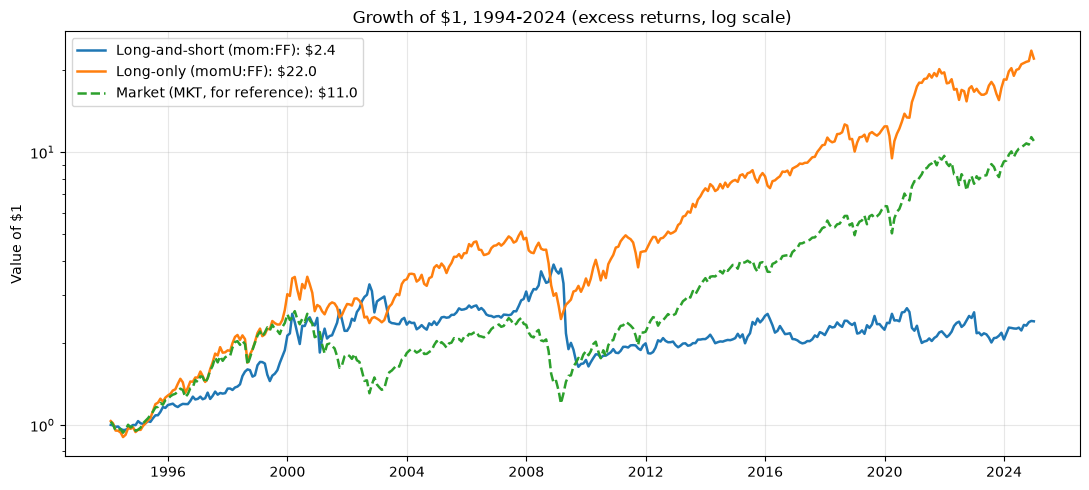

Momentum crash, Mar-May 2009: long-short -49.4%, long-only 15.2%


In [5]:
import matplotlib.pyplot as plt

cum = (1 + pd.concat([mom_ls, mom_lo, fac["MKT"].rename("Market (MKT, for reference)")], axis=1).loc[S94]).cumprod()

fig, ax = plt.subplots(figsize=(11, 5))
for col, ls in zip(cum.columns, ["-", "-", "--"]):
    ax.plot(cum.index, cum[col], ls=ls, lw=1.8, label=f"{col}: ${cum[col].iloc[-1]:.1f}")
ax.set_yscale("log")
ax.set_title("Growth of $1, 1994-2024 (excess returns, log scale)")
ax.set_ylabel("Value of $1")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

crash = slice("2009-03", "2009-05")
print(f"Momentum crash, Mar-May 2009: long-short {(1 + mom_ls.loc[crash]).prod() - 1:.1%}, "
      f"long-only {(1 + mom_lo.loc[crash]).prod() - 1:.1%}")

**(b) Is long-only as attractive on mean, volatility, and Sharpe?** On a stand-alone basis it looks *more* attractive. The long-only portfolio earned ≈ 11.6% per year vs. ≈ 4.3% for long-short, at similar volatility (≈ 17.8% vs. 16.7%), so its Sharpe ratio is much higher (≈ 0.65 vs. 0.26). It also has milder negative skew (≈ −0.44 vs. −1.46). But this comparison is misleading. Most of the long-only return is simply the **market premium**: its market beta is ≈ 1.03 and the market earned ≈ 9.0% over the period. Its alpha relative to MKT and HML is only ≈ 2.4% per year (t ≈ 1.75). The long-short portfolio has no market exposure to "borrow" returns from.

**(c) Is long-only as diversifying?** No. The long-only portfolio's correlation with the market is **≈ 0.90**, vs. **≈ −0.31** for long-short. Its correlation with HML is ≈ −0.12, only about half as negative as long-short's ≈ −0.21. The negative correlations are what made momentum valuable in 2.1(c): it pays off when the market and value do poorly. Long-only momentum is essentially **the market plus a small momentum tilt**, so it adds little diversification to a portfolio that already holds equities.

**(d) The plot** shows both sides of this. Long-only grows with the market (and a bit faster: ≈ \$22 vs. ≈ \$11 for MKT), while long-short has a much flatter path (≈ \$2.4) with a large drawdown in 2009. In the 2009 momentum crash (Mar–May), long-short lost ≈ 49% while long-only *gained* ≈ 15%. Long-only avoids the short side, which is where momentum crashes come from (beaten-down losers rebounding sharply).

# Section 2.3 - Is momentum robust to the choice of threshold?

In [6]:
top = lambda k: dec.iloc[:, -k:].mean(axis=1)            # equally weighted average of the top k deciles
bot = lambda k: dec.iloc[:, :k].mean(axis=1)             # ... and of the bottom k deciles
print("Decile columns (low to high):", list(dec.columns))

mom_d = {"momD1 (top 1 - bottom 1)": top(1) - bot(1),
         "momD3 (top 3 - bottom 3)": top(3) - bot(3),
         "momD5 (top 5 - bottom 5)": top(5) - bot(5)}
table3 = pd.DataFrame({k: table_stats(v) for k, v in mom_d.items()}).T.rename_axis("1994-2024")
display(table3.style.format(FMT))

display(pd.concat([table3.loc[["momD3 (top 3 - bottom 3)"]],
                   table2.loc[["Long-and-short (mom:FF)"]]]).style.format(FMT)
        .set_caption("(d) momD3 vs. the Fama-French construction"))

Decile columns (low to high): ['Lo PRIOR', 'PRIOR 2', 'PRIOR 3', 'PRIOR 4', 'PRIOR 5', 'PRIOR 6', 'PRIOR 7', 'PRIOR 8', 'PRIOR 9', 'Hi PRIOR']


,mean,vol,Sharpe,skewness,corr. to MKT,corr. to HML
1994-2024,,,,,,
momD1 (top 1 - bottom 1),8.10%,29.96%,0.27,-1.30,-0.32,-0.24
momD3 (top 3 - bottom 3),2.97%,19.37%,0.15,-1.34,-0.36,-0.21
momD5 (top 5 - bottom 5),1.73%,13.43%,0.13,-1.42,-0.35,-0.21


,mean,vol,Sharpe,skewness,corr. to MKT,corr. to HML
1994-2024,,,,,,
momD3 (top 3 - bottom 3),2.97%,19.37%,0.15,-1.34,-0.36,-0.21
Long-and-short (mom:FF),4.31%,16.72%,0.26,-1.46,-0.31,-0.21


**(b) Do the trade-offs match the theory?** Yes.

* **Mean falls as the portfolio becomes less extreme:** ≈ 8.1% (1 decile) → 3.0% (3 deciles) → 1.7% (5 deciles). Holding only the strongest winners and weakest losers captures the most momentum. Adding stocks closer to the middle of the ranking dilutes the signal.
* **Volatility also falls:** ≈ 30% → 19% → 13%. The 1-decile portfolio holds the fewest stocks (and the most extreme ones), so it carries the most idiosyncratic risk. Broader portfolios are more diversified.
* **Sharpe ratio is highest for the 1-decile construction** (≈ 0.27 vs. 0.15 and 0.13): the mean falls faster than the volatility as we widen the portfolio. This is *before* transaction costs. The 1-decile portfolio has the highest turnover, because stocks move in and out of the extreme deciles often, so its net-of-cost advantage would be smaller.
* Skewness (≈ −1.3 to −1.4) and correlations to MKT and HML (≈ −0.32 to −0.36 and ≈ −0.21 to −0.24) are similar across constructions. The momentum signal behaves the same way regardless of the threshold, which is evidence that it is a robust feature of the data rather than the result of choosing one particular cut-off.

**(c) Should AQR's retail product use a 1-decile or 5-decile construction?** Neither extreme is ideal. The 1-decile version has the best gross Sharpe ratio but ≈ 30% volatility, heavy concentration, and the highest turnover and trading costs, which is a poor fit for a low-cost retail fund. The 5-decile version is cheap and diversified, but its premium (≈ 1.7%) is so diluted that costs and fees would consume most of it. Something in between, such as the top **third** of stocks, balances signal strength against diversification and turnover. That is the construction AQR chose.

**(d) momD3 vs. the FF construction.** Both are 3-decile long-short portfolios, and their volatility, skewness, and correlations are similar. But momD3 earns less: ≈ 3.0% vs. ≈ 4.3% per year (Sharpe ≈ 0.15 vs. 0.26). The difference comes from size. The decile portfolios are value-weighted across all stocks, so they are dominated by large caps. The FF construction gives **equal weight to the small-stock and big-stock legs**. As 2.4 shows, momentum is stronger among small stocks, so giving them half the weight raises the FF factor's return.

# Section 2.4 - Is momentum driven by small stocks?

In [7]:
mom_S = (ss["SMALL HiPRIOR"] - ss["SMALL LoPRIOR"]).rename("Small stocks (momS)")
mom_B = (ss["BIG HiPRIOR"] - ss["BIG LoPRIOR"]).rename("Large stocks (momB)")

table4 = pd.DataFrame({s.name: table_stats(s, corr_hml=False)
                       for s in [umd.rename("All stocks (mom:FF)"), mom_S, mom_B]}).T.rename_axis("1994-2024")
display(table4.style.format(FMT))
print(f"Correlation between small- and big-stock momentum (1994-2024): {mom_S.loc[S94].corr(mom_B.loc[S94]):.2f}")

,mean,vol,Sharpe,skewness,corr. to MKT
1994-2024,,,,,
All stocks (mom:FF),4.31%,16.72%,0.26,-1.46,-0.31
Small stocks (momS),6.14%,16.91%,0.36,-1.80,-0.31
Large stocks (momB),2.46%,18.23%,0.14,-0.87,-0.28


Correlation between small- and big-stock momentum (1994-2024): 0.81


**(b) Is momentum's attractiveness mostly driven by small stocks?** Largely, yes.

* **Small-stock momentum** earned ≈ 6.1% per year with a Sharpe ratio of ≈ 0.36.
* **Large-stock momentum** earned only ≈ 2.5% per year, at slightly *higher* volatility (≈ 18.2% vs. 16.9%), so its Sharpe ratio is ≈ 0.14, well under half that of small stocks.
* The FF factor is the average of the two legs, so it sits in between (≈ 4.3%, Sharpe ≈ 0.26).

So a momentum strategy in large stocks still delivers a **positive** premium, but not at comparable risk: it earns less than half as much per unit of volatility. On the plus side, large-stock momentum has much milder negative skew (≈ −0.87 vs. −1.80 for small), and the two are highly correlated (≈ 0.81), so the large-stock version still captures the same underlying signal and the same negative correlation to the market (≈ −0.28). These numbers are before costs. Small stocks are more expensive to trade, which narrows the gap in practice, but large-cap momentum gives up a substantial part of the premium.

# Section 2.5 - Assessment of the AQR retail product

The case describes a **long-only** product that buys the momentum winners among **large (and, in one version, mid-sized) stocks**. Based on 2.1–2.4, it captures some, but not all, of the important features of the Fama-French momentum factor.

**What it keeps**

* **The momentum signal itself.** The long side of momentum earns an alpha over MKT and HML (≈ 2.4% per year since 1994), and the effect is robust to the choice of threshold (2.3).
* **Practicality for retail investors.** It is long-only, so there is no shorting, borrowing cost, or margin. It holds liquid large caps, which lowers trading costs and suits regulatory constraints. A top-third construction avoids the turnover of a 1-decile portfolio.
* **Protection from momentum crashes.** Crashes come from the short side. In Mar–May 2009 long-short momentum lost ≈ 49% while the long-only version gained ≈ 15%.

**What it loses**

* **Diversification.** This is the main reason momentum belongs in an ideal portfolio (2.1c): long-short momentum is *negatively* correlated with the market and value. The long-only product has a correlation of ≈ 0.90 with the market. It is mostly market beta with a momentum tilt, so investors who already own equities gain relatively little.
* **Much of the premium.** Focusing on large stocks gives up a large part of the return: large-stock momentum has a Sharpe ratio of ≈ 0.14 vs. ≈ 0.36 for small stocks (2.4). Momentum has also been weak since the case was written: the FF factor earned ≈ −1.3% per year over 2009–2024 (2.1).

**Suggested modifications**

1. **Benchmark and market it honestly**: as an equity fund with a momentum tilt, evaluated against the market (its alpha and tracking error), not as a stand-alone momentum strategy.
2. **Include mid-caps** (as in AQR's mid-cap version), where momentum is stronger than in mega-caps but trading is still affordable.
3. **Offer a way to get the diversifying exposure**: for example, a version that hedges part of the market beta (e.g. with index futures), or a long-short version for investors who can use one.
4. **Combine momentum with value.** The two are negatively correlated (≈ −0.1 to −0.5 across subsamples in 2.1), so a combined value-momentum tilt is more diversified and less exposed to momentum's drawdowns.
5. **Keep a moderate threshold** (around the top third) and control turnover, e.g. through the rebalancing frequency, because costs matter more for a retail product than the small gross Sharpe advantage of a more concentrated portfolio.

## Citations

Claude Opus 5.5 (Anthropic) was used to assist with the code, writing, and analysis in this notebook, including Sections 2.2–2.5.